# Week 7: pandas DataFrames with CU Hockey Data (Answer Key)

Last time we stored many values in **lists**. Real data usually looks like a **table**: rows of records, columns of fields. **pandas** is Python's library for working with tables.

Our data: real stats for three **CU Boulder club hockey** teams, from the ACHA and Big Mountain Hockey Conference websites.

| Team | Seasons |
|---|---|
| CU Men's D1 | 2024-25 |
| CU Men's D2 | 2023-24 and 2026-27 (in progress) |
| CU Women's D1 | 2024-25 |

By the end of class you should be able to:
- Create a DataFrame and load one from a CSV file
- Inspect a DataFrame (`head`, `shape`, `dtypes`, `info`, `describe`)
- Select columns and filter rows
- Sort, and add new columns
- Summarize with `value_counts` and `groupby`
- Handle missing values and dates
- Combine two tables with `merge`

Cells marked **✏️ Your turn** are for you to fill in.

## 0. Setup

We import pandas with the short name `pd`. Everyone does this, so you'll see `pd.` in every example online.

If you get `ModuleNotFoundError: No module named 'pandas'`, run `pip install pandas` in a terminal (or `%pip install pandas` in a cell).

In [1]:
import pandas as pd

pd.set_option("display.max_columns", 20)   # show more columns
pd.set_option("display.width", 120)

print(pd.__version__)

2.3.3


## 1. From Lists to Series and DataFrames

A **Series** is like a list, but each value has a **label** (the **index**).

A **DataFrame** is a table: a set of Series that share the same index. Each column is a Series.

In [2]:
# A list of goals, and a Series with player names as labels
goals_list = [13, 9, 16]
goals = pd.Series(goals_list, index=["McConaughy", "Marcinkevicius", "Hoftiezer"])

print(goals)
print()
print(goals["Hoftiezer"])   # look up by label
print(goals.sum())          # built-in math

McConaughy        13
Marcinkevicius     9
Hoftiezer         16
dtype: int64

16
38


⚠️ **Lists and Series behave differently with math.** `list * 2` repeats the list (last week). `Series * 2` multiplies every value.

In [3]:
print(goals_list * 2)   # list: repeats
print(goals * 2)        # Series: multiplies each value

[13, 9, 16, 13, 9, 16]
McConaughy        26
Marcinkevicius    18
Hoftiezer         32
dtype: int64


You can build a DataFrame from a **list of lists** (one inner list per row) or from a **dictionary of lists** (one list per column).

In [4]:
# From a list of lists: one row per team
rows = [
    ["CU Men's D1",   "WCHL",  1],
    ["CU Men's D2",   "BMHC",  2],
    ["CU Women's D1", "WWCHL", 1],
]
teams = pd.DataFrame(rows, columns=["team", "conference", "division"])
teams

,team,conference,division
0,CU Men's D1,WCHL,1
1,CU Men's D2,BMHC,2
2,CU Women's D1,WWCHL,1


In [5]:
# From a dictionary: one list per column
teams = pd.DataFrame({
    "team":       ["CU Men's D1", "CU Men's D2", "CU Women's D1"],
    "conference": ["WCHL", "BMHC", "WWCHL"],
    "division":   [1, 2, 1],
})
teams

,team,conference,division
0,CU Men's D1,WCHL,1
1,CU Men's D2,BMHC,2
2,CU Women's D1,WWCHL,1


## 2. Loading and Inspecting Data

Most of the time you load data from a file. `pd.read_csv()` reads a CSV file into a DataFrame.

| File | One row per |
|---|---|
| `cu_games.csv` | game |
| `cu_skaters.csv` | player per team-season (scoring stats) |
| `cu_goalies.csv` | goalie per team-season |
| `cu_rosters.csv` | rostered player (height, weight, hometown) |

In [6]:
games   = pd.read_csv("cu_hockey_data/cu_games.csv")
skaters = pd.read_csv("cu_hockey_data/cu_skaters.csv")
goalies = pd.read_csv("cu_hockey_data/cu_goalies.csv")
rosters = pd.read_csv("cu_hockey_data/cu_rosters.csv")

games.head()      # first 5 rows

,team,season,game_id,date,day,home_away,opponent,opponent_division,venue,cu_goals,opp_goals,result,status,start_time
0,CU Men's D1,2024-25,20462,2024-09-06,Fri,Home,Midland University,MD1,CU Boulder Rec Center Ice Rink (CO),0.0,3.0,L,Final,NaN
1,CU Men's D1,2024-25,21847,2024-09-07,Sat,Home,Midland University,MD1,CU Boulder Rec Center Ice Rink (CO),3.0,2.0,W,Final SO,NaN
2,CU Men's D1,2024-25,20464,2024-09-13,Fri,Home,University of Central Oklahoma,MD1,CU Boulder Rec Center Ice Rink (CO),5.0,3.0,W,Final,NaN
3,CU Men's D1,2024-25,20465,2024-09-14,Sat,Home,University of Central Oklahoma,MD1,CU Boulder Rec Center Ice Rink (CO),3.0,1.0,W,Final,NaN
4,CU Men's D1,2024-25,20532,2024-09-20,Fri,Away,University of Utah,MD1,Salt Lake City Sports Complex (UT),1.0,0.0,W,Final SO,NaN


The first things to check on any new dataset:

| Code | Tells you |
|---|---|
| `df.head(n)` / `df.tail(n)` | first / last `n` rows |
| `df.shape` | (rows, columns) |
| `df.columns` | column names |
| `df.dtypes` | the data type of each column |
| `df.info()` | all of the above, plus missing-value counts |
| `df.describe()` | summary statistics for number columns |

In [7]:
print(games.shape)
print(games.columns.tolist())

(117, 14)
['team', 'season', 'game_id', 'date', 'day', 'home_away', 'opponent', 'opponent_division', 'venue', 'cu_goals', 'opp_goals', 'result', 'status', 'start_time']


In [8]:
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   team               117 non-null    object 
 1   season             117 non-null    object 
 2   game_id            117 non-null    int64  
 3   date               117 non-null    object 
 4   day                117 non-null    object 
 5   home_away          117 non-null    object 
 6   opponent           117 non-null    object 
 7   opponent_division  117 non-null    object 
 8   venue              117 non-null    object 
 9   cu_goals           97 non-null     float64
 10  opp_goals          97 non-null     float64
 11  result             97 non-null     object 
 12  status             117 non-null    object 
 13  start_time         20 non-null     object 
dtypes: float64(2), int64(1), object(11)
memory usage: 12.9+ KB


Notice `cu_goals` is `float64`, not `int64`, and has fewer non-null values than the other columns. That's because the 2026-27 season isn't over: future games have no score yet. We'll come back to that in section 8.

In [9]:
skaters.describe()

,player_id,jersey,gp,goals,assists,points,points_per_game,pp_goals,sh_goals,gw_goals,shootout_gw_goals,pim
count,120.000000,113.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,113.000000,120.000000,120.000000,113.000000
mean,23839.400000,27.601770,15.908333,2.700000,3.783333,6.483333,0.372083,0.383333,0.141593,0.408333,0.016667,10.663717
std,10956.907574,24.428299,11.149855,3.749734,4.087660,7.282976,0.341031,0.909181,0.532301,0.854998,0.128556,16.565676
min,3730.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,15842.750000,10.000000,5.000000,0.000000,1.000000,1.000000,0.087500,0.000000,0.000000,0.000000,0.000000,2.000000
50%,23276.500000,21.000000,17.000000,1.000000,3.000000,4.000000,0.320000,0.000000,0.000000,0.000000,0.000000,4.000000
75%,29622.250000,34.000000,26.000000,4.000000,6.000000,10.000000,0.567500,0.000000,0.000000,0.250000,0.000000,14.000000
max,42806.000000,99.000000,36.000000,19.000000,19.000000,33.000000,1.710000,6.000000,4.000000,5.000000,1.000000,109.000000


### ✏️ Your turn
1. How many rows and columns does `rosters` have?
2. Show the **last 3** rows of `skaters`.

In [10]:
# ✅ Answer
print(rosters.shape)
skaters.tail(3)

(84, 14)


,team,season,player_id,jersey,name,pos,rookie,gp,goals,assists,points,points_per_game,pp_goals,sh_goals,gw_goals,shootout_gw_goals,pim
117,CU Men's D2,2026-27,27168,31.0,Caleb Allen,G,False,3,0,0,0,0.0,0,0.0,0,0,0.0
118,CU Men's D2,2026-27,42794,1.0,William Baker,G,True,3,0,0,0,0.0,0,0.0,0,0,0.0
119,CU Men's D2,2026-27,42801,15.0,Anders Morrison,LW,True,3,0,0,0,0.0,0,0.0,0,0,0.0


## 3. Selecting Columns

- One column, with single brackets: `df["name"]` gives a **Series**.
- Several columns, with a **list** inside the brackets: `df[["name", "points"]]` gives a **DataFrame**.

In [11]:
names = skaters["name"]
print(type(names))
names.head()

<class 'pandas.core.series.Series'>


0           Drew McConaughy
1    Rapolas Marcinkevicius
2           David Hoftiezer
3           Jacob Rosolanko
4              Elliot Testa
Name: name, dtype: object

In [12]:
skaters[["name", "team", "points"]].head()

,name,team,points
0,Drew McConaughy,CU Men's D1,30
1,Rapolas Marcinkevicius,CU Men's D1,28
2,David Hoftiezer,CU Men's D1,27
3,Jacob Rosolanko,CU Men's D1,15
4,Elliot Testa,CU Men's D1,15


A column is a Series, so it has methods like `sum`, `mean`, `max` and `min`. `tolist()` turns it back into a plain Python list.

In [13]:
print("Total goals:", skaters["goals"].sum())
print("Most points by one player:", skaters["points"].max())
print("Average points per player:", round(skaters["points"].mean(), 2))
print(skaters["name"].tolist()[:5])

Total goals: 324
Most points by one player: 33
Average points per player: 6.48
['Drew McConaughy', 'Rapolas Marcinkevicius', 'David Hoftiezer', 'Jacob Rosolanko', 'Elliot Testa']


⚠️ **Common mistake:** forgetting the inner list when selecting several columns.

In [14]:
try:
    skaters["name", "points"]          # wrong: needs [["name", "points"]]
except KeyError as err:
    print("KeyError:", err)

KeyError: ('name', 'points')


### ✏️ Your turn
1. Show the `name`, `pos`, `goals` and `assists` columns of `skaters`.
2. What is the most penalty minutes (`pim`) any player had?

In [15]:
# ✅ Answer
print(skaters["pim"].max())
skaters[["name", "pos", "goals", "assists"]]

109.0


,name,pos,goals,assists
0,Drew McConaughy,F,13,17
1,Rapolas Marcinkevicius,F,9,19
2,David Hoftiezer,F,16,11
3,Jacob Rosolanko,F,11,4
4,Elliot Testa,F,6,9
...,...,...,...,...
115,Harrison Smith,G,0,0
116,Evan Stellino,D,0,0
117,Caleb Allen,G,0,0
118,William Baker,G,0,0


## 4. Filtering Rows

A comparison on a column gives a Series of `True`/`False`, called a **boolean mask**. Putting the mask in brackets keeps only the `True` rows.

In [16]:
mask = skaters["points"] >= 20
mask.head()

0     True
1     True
2     True
3    False
4    False
Name: points, dtype: bool

In [17]:
skaters[mask][["team", "season", "name", "points"]]

,team,season,name,points
0,CU Men's D1,2024-25,Drew McConaughy,30
1,CU Men's D1,2024-25,Rapolas Marcinkevicius,28
2,CU Men's D1,2024-25,David Hoftiezer,27
30,CU Men's D2,2023-24,Diego Pitones,24
60,CU Women's D1,2024-25,Mia Fiscelli,33
61,CU Women's D1,2024-25,Natalie Ewald,23
62,CU Women's D1,2024-25,Jordan Bonk,23


Combine conditions with `&` (and), `|` (or) and `~` (not). **Each condition needs its own parentheses.**

In [18]:
women_scorers = skaters[(skaters["team"] == "CU Women's D1") & (skaters["goals"] >= 5)]
women_scorers[["name", "goals", "assists", "points"]]

,name,goals,assists,points
60,Mia Fiscelli,19,14,33
61,Natalie Ewald,15,8,23
62,Jordan Bonk,5,18,23
63,Anna Masiello,8,10,18
64,Amanda Wallace,9,8,17
65,Brianna Arens,7,10,17


⚠️ **Common mistake:** using Python's `and`/`or` with pandas. They work on single `True`/`False` values, not on whole columns.

In [19]:
try:
    skaters[(skaters["goals"] >= 5) and (skaters["pim"] > 20)]
except ValueError as err:
    print("ValueError:", err)

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().


Other handy filters:
- `.isin([...])`: is the value in this list?
- `.str.contains("text")`: does the text contain this?
- `df.loc[rows, columns]`: filter rows and pick columns in one step
- `df.iloc[0:3]`: select rows by **position**, like list slicing

In [20]:
rivals = ["University of Denver", "Colorado State University"]
games[games["opponent"].isin(rivals)][["team", "date", "home_away", "opponent", "cu_goals", "opp_goals"]]

,team,date,home_away,opponent,cu_goals,opp_goals
6,CU Men's D1,2024-09-27,Away,Colorado State University,5.0,6.0
7,CU Men's D1,2024-09-28,Home,Colorado State University,3.0,4.0
19,CU Men's D1,2024-12-06,Home,Colorado State University,3.0,2.0
20,CU Men's D1,2024-12-07,Away,Colorado State University,7.0,3.0
34,CU Men's D1,2025-02-21,Away,Colorado State University,1.0,2.0
35,CU Men's D1,2025-02-22,Home,Colorado State University,1.0,3.0
36,CU Men's D2,2023-09-22,Home,University of Denver,2.0,3.0
37,CU Men's D2,2023-09-23,Away,University of Denver,3.0,6.0
42,CU Men's D2,2023-10-14,Away,University of Denver,1.0,4.0
50,CU Men's D2,2023-12-08,Home,Colorado State University,2.0,1.0


In [21]:
skaters.loc[skaters["pim"] > 50, ["name", "team", "season", "pim"]]

,name,team,season,pim
7,Roman Di Domizio,CU Men's D1,2024-25,109.0
9,Blake Blevins,CU Men's D1,2024-25,108.0


In [22]:
skaters.iloc[0:3]

,team,season,player_id,jersey,name,pos,rookie,gp,goals,assists,points,points_per_game,pp_goals,sh_goals,gw_goals,shootout_gw_goals,pim
0,CU Men's D1,2024-25,9125,9.0,Drew McConaughy,F,False,36,13,17,30,0.83,3,4.0,1,1,6.0
1,CU Men's D1,2024-25,23270,26.0,Rapolas Marcinkevicius,F,False,33,9,19,28,0.85,1,3.0,1,0,16.0
2,CU Men's D1,2024-25,23314,91.0,David Hoftiezer,F,False,35,16,11,27,0.77,3,1.0,4,1,39.0


### ✏️ Your turn
1. Show all **home** games for **CU Women's D1**.
2. Show the **rookies** (`rookie` is `True`) who scored at least 1 point. Show `name`, `team`, `season` and `points`.

In [23]:
# ✅ Answer
women_home = games[(games["team"] == "CU Women's D1") & (games["home_away"] == "Home")]
display(women_home)

skaters.loc[skaters["rookie"] & (skaters["points"] >= 1), ["name", "team", "season", "points"]]

,team,season,game_id,date,day,home_away,opponent,opponent_division,venue,cu_goals,opp_goals,result,status,start_time
64,CU Women's D1,2024-25,21076,2024-09-27,Fri,Home,University of Utah,WD1,University Of Colorado Boulder Recreation Center,3.0,2.0,W,Final,NaN
65,CU Women's D1,2024-25,21077,2024-09-28,Sat,Home,University of Utah,WD1,University Of Colorado Boulder Recreation Center,3.0,1.0,W,Final,NaN
72,CU Women's D1,2024-25,21078,2024-11-01,Fri,Home,University of Wyoming,WD1,University Of Colorado Boulder Recreation Center,7.0,0.0,W,Final,NaN
73,CU Women's D1,2024-25,21079,2024-11-02,Sat,Home,University of Wyoming,WD1,University Of Colorado Boulder Recreation Center,15.0,0.0,W,Final,NaN
74,CU Women's D1,2024-25,21080,2024-11-08,Fri,Home,Montana State University,WD1,University Of Colorado Boulder Recreation Center,5.0,0.0,W,Final,NaN
75,CU Women's D1,2024-25,21081,2024-11-09,Sat,Home,Montana State University,WD1,University Of Colorado Boulder Recreation Center,3.0,2.0,W,Final OT,NaN
78,CU Women's D1,2024-25,21082,2024-11-22,Fri,Home,University of Minnesota,WD1,University Of Colorado Boulder Recreation Center,2.0,3.0,OTL,Final OT,NaN
79,CU Women's D1,2024-25,21083,2024-11-23,Sat,Home,University of Minnesota,WD1,University Of Colorado Boulder Recreation Center,3.0,2.0,W,Final OT,NaN
80,CU Women's D1,2024-25,21084,2025-01-24,Fri,Home,Miami University,WD1,University Of Colorado Boulder Recreation Center,3.0,4.0,L,Final,NaN
81,CU Women's D1,2024-25,21085,2025-01-25,Sat,Home,Miami University,WD1,University Of Colorado Boulder Recreation Center,1.0,5.0,L,Final,NaN


,name,team,season,points
34,Garrett Covney,CU Men's D2,2023-24,16
44,Nickita Alexeyev,CU Men's D2,2023-24,6
48,Brandon Hackett,CU Men's D2,2023-24,4
50,Emanuel Wetschnig,CU Men's D2,2023-24,3
51,Kai Phipps,CU Men's D2,2023-24,3
54,Shawn Valdez,CU Men's D2,2023-24,1
72,Zoe Dupuis,CU Women's D1,2024-25,6
76,Abigail Zahn,CU Women's D1,2024-25,2
87,Ethan Mceneany,CU Men's D2,2026-27,10
91,Stephen Schaefer,CU Men's D2,2026-27,6


## 5. Sorting

`sort_values()` sorts by one or more columns. `ascending=False` puts the largest first. `nlargest(n, column)` is a shortcut for the top `n`.

In [24]:
cols = ["team", "season", "name", "goals", "assists", "points"]
skaters.sort_values("points", ascending=False)[cols].head(10)

,team,season,name,goals,assists,points
60,CU Women's D1,2024-25,Mia Fiscelli,19,14,33
0,CU Men's D1,2024-25,Drew McConaughy,13,17,30
1,CU Men's D1,2024-25,Rapolas Marcinkevicius,9,19,28
2,CU Men's D1,2024-25,David Hoftiezer,16,11,27
30,CU Men's D2,2023-24,Diego Pitones,10,14,24
62,CU Women's D1,2024-25,Jordan Bonk,5,18,23
61,CU Women's D1,2024-25,Natalie Ewald,15,8,23
31,CU Men's D2,2023-24,David Levkus,9,10,19
63,CU Women's D1,2024-25,Anna Masiello,8,10,18
65,CU Women's D1,2024-25,Brianna Arens,7,10,17


In [25]:
# Sort by team A-Z, then by points high to low within each team
skaters.sort_values(["team", "points"], ascending=[True, False])[cols].head(8)

,team,season,name,goals,assists,points
0,CU Men's D1,2024-25,Drew McConaughy,13,17,30
1,CU Men's D1,2024-25,Rapolas Marcinkevicius,9,19,28
2,CU Men's D1,2024-25,David Hoftiezer,16,11,27
3,CU Men's D1,2024-25,Jacob Rosolanko,11,4,15
4,CU Men's D1,2024-25,Elliot Testa,6,9,15
5,CU Men's D1,2024-25,Douglas Wood,3,12,15
6,CU Men's D1,2024-25,Owen Dickinson,5,9,14
7,CU Men's D1,2024-25,Roman Di Domizio,6,7,13


In [26]:
skaters.nlargest(5, "pim")[["name", "team", "season", "pim"]]

,name,team,season,pim
7,Roman Di Domizio,CU Men's D1,2024-25,109.0
9,Blake Blevins,CU Men's D1,2024-25,108.0
2,David Hoftiezer,CU Men's D1,2024-25,39.0
14,Jack Ferguson,CU Men's D1,2024-25,36.0
22,Michael Rhein,CU Men's D1,2024-25,36.0


### ✏️ Your turn
1. Show the top 5 **goal** scorers on **CU Women's D1**.
2. Among goalies who played **at least 5 games**, who had the best (highest) `save_pct`?

In [27]:
# ✅ Answer
women = skaters[skaters["team"] == "CU Women's D1"]
display(women.nlargest(5, "goals")[["name", "goals", "points"]])

goalies[goalies["gp"] >= 5].sort_values("save_pct", ascending=False)[["name", "team", "season", "gp", "save_pct"]]

,name,goals,points
60,Mia Fiscelli,19,33
61,Natalie Ewald,15,23
64,Amanda Wallace,9,17
63,Anna Masiello,8,18
65,Brianna Arens,7,17


,name,team,season,gp,save_pct
1,Caiden Boucher,CU Men's D1,2024-25,5,0.951
7,Zoe Watson,CU Women's D1,2024-25,15,0.946
8,Andi Bierbaum,CU Women's D1,2024-25,13,0.918
2,Liam O'Gwen,CU Men's D1,2024-25,32,0.915
5,Dylan Lawrence,CU Men's D2,2023-24,10,0.891
6,Abram Seigel,CU Men's D2,2023-24,19,0.891


## 6. Adding Columns

Assign to a new column name. The calculation runs on **every row at once**, with no loop needed.

In [28]:
games["goal_diff"] = games["cu_goals"] - games["opp_goals"]
games["win"] = games["result"] == "W"

games[["team", "date", "opponent", "cu_goals", "opp_goals", "goal_diff", "win"]].head()

,team,date,opponent,cu_goals,opp_goals,goal_diff,win
0,CU Men's D1,2024-09-06,Midland University,0.0,3.0,-3.0,False
1,CU Men's D1,2024-09-07,Midland University,3.0,2.0,1.0,True
2,CU Men's D1,2024-09-13,University of Central Oklahoma,5.0,3.0,2.0,True
3,CU Men's D1,2024-09-14,University of Central Oklahoma,3.0,1.0,2.0,True
4,CU Men's D1,2024-09-20,University of Utah,1.0,0.0,1.0,True


In [29]:
# Biggest wins
games.sort_values("goal_diff", ascending=False)[["team", "date", "opponent", "cu_goals", "opp_goals"]].head(3)

,team,date,opponent,cu_goals,opp_goals
73,CU Women's D1,2024-11-02,University of Wyoming,15.0,0.0
48,CU Men's D2,2023-11-18,Idaho State University,14.0,1.0
39,CU Men's D2,2023-09-30,University of Wyoming,8.0,1.0


In [30]:
rosters["height_ft"] = (rosters["height_in"] / 12).round(2)
rosters[["name", "height", "height_in", "height_ft"]].head()

,name,height,height_in,height_ft
0,Drew McConaughy,5-10,70,5.83
1,Jacob Rosolanko,6-0,72,6.00
2,Logan Behrje,6-0,72,6.00
3,Michael Rhein,6-0,72,6.00
4,Blake Blevins,6-1,73,6.08


### ✏️ Your turn
1. Add a column `total_goals` to `games` (both teams' goals added together).
2. Find the highest-scoring game.

In [31]:
# ✅ Answer
games["total_goals"] = games["cu_goals"] + games["opp_goals"]
games.nlargest(1, "total_goals")[["team", "date", "opponent", "cu_goals", "opp_goals", "total_goals"]]

,team,date,opponent,cu_goals,opp_goals,total_goals
48,CU Men's D2,2023-11-18,Idaho State University,14.0,1.0,15.0


## 7. Counting and Grouping

`value_counts()` counts how often each value appears.

In [32]:
games["result"].value_counts()

result
W      51
L      43
OTL     2
SOL     1
Name: count, dtype: int64

`groupby()` does three things:
1. **Split** the rows into groups (for example, by team)
2. **Apply** a calculation to each group (sum, mean, count...)
3. **Combine** the results into a new table

```python
df.groupby("group_column")["value_column"].calculation()
```

In [33]:
# W / L / OTL (overtime loss) / SOL (shootout loss) for each team-season
record = games.groupby(["team", "season"])["result"].value_counts().unstack(fill_value=0)
record

result                  L  OTL  SOL   W
team          season                   
CU Men's D1   2024-25  16    1    1  18
CU Men's D2   2023-24  20    0    0   8
              2026-27   1    0    0   6
CU Women's D1 2024-25   6    1    0  19

⚠️ **Watch out for games that haven't been played.** `win` is `False` for future games too, which would make the 2026-27 team look worse than it is. Filter to played games first.

In [34]:
played = games[games["status"] != "Scheduled"]
print(len(games), "games in the file,", len(played), "played")

played.groupby(["team", "home_away"])["win"].mean().round(3)

117 games in the file, 97 played


team           home_away
CU Men's D1    Away         0.450
               Home         0.562
CU Men's D2    Away         0.389
               Home         0.412
CU Women's D1  Away         0.727
               Home         0.733
Name: win, dtype: float64

`agg()` computes several summaries at once. Each one is written as `new_name=(column, calculation)`.

In [35]:
summary = played.groupby(["team", "season"]).agg(
    games=("game_id", "count"),
    goals_for=("cu_goals", "sum"),
    goals_against=("opp_goals", "sum"),
    win_pct=("win", "mean"),
)
summary["win_pct"] = summary["win_pct"].round(3)
summary

games  goals_for  goals_against  win_pct
team          season                                           
CU Men's D1   2024-25     36      110.0          110.0    0.500
CU Men's D2   2023-24     28       94.0          114.0    0.286
              2026-27      7       35.0           11.0    0.857
CU Women's D1 2024-25     26       87.0           53.0    0.731

In [36]:
# Are defensemen taller than forwards? Group by team too, so men and women aren't mixed
rosters.groupby(["team", "position_group"])["height_in"].mean().round(1).unstack()

position_group,Defense,Forwards,Goalies
team,,,
CU Men's D1,72.2,71.5,72.2
CU Men's D2,71.4,70.8,70.7
CU Women's D1,65.8,64.4,68.0


### ✏️ Your turn
1. For **CU Men's D1**, what is the average `points` by position (`pos`)?
2. Which **day of the week** (`day`) has the most games?

In [37]:
# ✅ Answer
men_d1 = skaters[skaters["team"] == "CU Men's D1"]
display(men_d1.groupby("pos")["points"].mean().round(2))

games["day"].value_counts()

pos
D     5.09
F    13.87
G     0.25
Name: points, dtype: float64

day
Fri    50
Sat    48
Sun    13
Thu     4
Mon     2
Name: count, dtype: int64

## 8. Missing Data

pandas marks missing values as `NaN` ("not a number"). Our data has two kinds:
- Future games, which have no score yet
- Women's player weights, which the league site doesn't list

In [38]:
games.isna().sum()

team                  0
season                0
game_id               0
date                  0
day                   0
home_away             0
opponent              0
opponent_division     0
venue                 0
cu_goals             20
opp_goals            20
result               20
status                0
start_time           97
goal_diff            20
win                   0
total_goals          20
dtype: int64

In [39]:
upcoming = games[games["cu_goals"].isna()]
upcoming[["team", "date", "opponent", "home_away", "start_time"]].head()

,team,date,opponent,home_away,start_time
97,CU Men's D2,2026-10-17,Boston University,Home,8:00 pm MDT
98,CU Men's D2,2026-10-23,University of Denver,Home,5:00 pm MDT
99,CU Men's D2,2026-10-24,University of Denver,Home,3:00 pm MDT
100,CU Men's D2,2026-10-30,Colorado State University,Away,8:30 pm MDT
101,CU Men's D2,2026-11-06,Metropolitan State University-Denver,Home,8:00 pm MDT


In [40]:
print("Missing weights:", rosters["weight_lb"].isna().sum())

# Calculations like mean() skip NaN, so a team with no weights gives NaN
rosters.groupby("team")["weight_lb"].mean().round(1)

Missing weights: 26


team
CU Men's D1      179.8
CU Men's D2      178.7
CU Women's D1      NaN
Name: weight_lb, dtype: float64

Three common fixes:
- `dropna(subset=[...])` removes rows that are missing a value in those columns
- `fillna(value)` replaces missing values
- Or just keep them. Missing doesn't mean zero, and filling in 0 would be wrong for a weight!

In [41]:
print(len(games.dropna(subset=["cu_goals"])), "games with a score")

games["start_time"].fillna("played").head()

97 games with a score


0    played
1    played
2    played
3    played
4    played
Name: start_time, dtype: object

## 9. Dates

The `date` column was read as plain text (`object`). `pd.to_datetime()` converts it to real dates, which can be compared and sorted, and which give us the `.dt` tools.

In [42]:
print(games["date"].dtype)
games["date"] = pd.to_datetime(games["date"])
print(games["date"].dtype)

object
datetime64[ns]


In [43]:
games["month"] = games["date"].dt.month_name()
games["month"].value_counts()

month
January      30
November     23
October      22
September    18
February     18
December      6
Name: count, dtype: int64

In [44]:
# Upcoming games after the day this data was pulled (Oct 14, 2026)
games[games["date"] > "2026-10-14"][["date", "opponent", "home_away", "venue", "start_time"]].head()

,date,opponent,home_away,venue,start_time
97,2026-10-17,Boston University,Home,EPIC - Edora Pool Ice Center (CO),8:00 pm MDT
98,2026-10-23,University of Denver,Home,CU Boulder Rec Center Ice Rink (CO),5:00 pm MDT
99,2026-10-24,University of Denver,Home,CU Boulder Rec Center Ice Rink (CO),3:00 pm MDT
100,2026-10-30,Colorado State University,Away,EPIC - Edora Pool Ice Center (CO),8:30 pm MDT
101,2026-11-06,Metropolitan State University-Denver,Home,CU Boulder Rec Center Ice Rink (CO),8:00 pm MDT


## 10. Combining Tables with `merge`

`skaters` has scoring stats, and `rosters` has height, weight and hometown. They share `player_id` and `season`, so we can join them, like a lookup in Excel.

`how="left"` keeps every row of the left table (`skaters`), even when there's no match. `indicator=True` adds a `_merge` column that says where each row came from.

In [45]:
roster_cols = ["player_id", "season", "height_in", "weight_lb", "shoots", "hometown_state"]
merged = skaters.merge(rosters[roster_cols], on=["player_id", "season"], how="left", indicator=True)

merged["_merge"].value_counts()

_merge
both          84
left_only     36
right_only     0
Name: count, dtype: int64

In [46]:
# Who has stats but no roster entry?
no_roster = merged[merged["_merge"] == "left_only"]
no_roster.groupby(["team", "season"])["name"].count()

team         season 
CU Men's D2  2023-24     2
             2026-27    34
Name: name, dtype: int64

Most of those are the 2026-27 team, because we don't have that season's roster. Two 2023-24 players have stats but aren't on the roster. That happens with real data!

Now we can ask questions that need both tables:

In [47]:
# Do left-handed or right-handed shooters score more?
merged.groupby("shoots")["goals"].mean().round(2)

shoots
L    3.66
R    3.18
Name: goals, dtype: float64

In [48]:
# Players on both Men's D2 teams (2023-24 and 2026-27)
d2_2324 = skaters[(skaters["team"] == "CU Men's D2") & (skaters["season"] == "2023-24")]
d2_2627 = skaters[(skaters["team"] == "CU Men's D2") & (skaters["season"] == "2026-27")]

both = d2_2324.merge(d2_2627, on="player_id", suffixes=("_2324", "_2627"))
both[["name_2324", "gp_2324", "points_2324", "gp_2627", "points_2627"]]

,name_2324,gp_2324,points_2324,gp_2627,points_2627
0,Garrett Covney,26,16,2,1
1,Marius Krasauskas,25,9,7,5
2,Kory Diponio,9,6,7,6
3,Brandon Hackett,20,4,0,0
4,Dylan Lawrence,10,0,0,0


### ✏️ Your turn
Using `merged`, which **home state** produced the most total points? Show the top 5.

In [49]:
# ✅ Answer
merged.groupby("hometown_state")["points"].sum().sort_values(ascending=False).head(5)

hometown_state
CO    328
NJ     83
OH     54
IL     40
MN     31
Name: points, dtype: int64

## 11. Bonus: Cleaning Data As Scraped

The files above were already cleaned. The `as_scraped/` folder has the tables as the websites showed them. Real data almost always needs cleaning first.

In [50]:
raw = pd.read_csv("cu_hockey_data/as_scraped/schedule_md2_2026_27.csv")
print(raw.dtypes)
raw.tail(3)

Date           object
Visiting       object
Visiting GF    object
Home           object
Home GF        object
Venue          object
Time           object
Game ID         int64
dtype: object


,Date,Visiting,Visiting GF,Home,Home GF,Venue,Time,Game ID
24,"Thu, Jan 28",MD2 University of Colorado,-,MD2 Grand Canyon University,-,Fire 'n' Ice Sports Arena (AZ),7:00 pm MST,34649
25,"Fri, Jan 29",MD2 University of Colorado,-,MD2 Northern Arizona University,-,Jay Lively Arena (AZ),8:30 pm MDT,33695
26,"Sat, Jan 30",MD2 University of Colorado,-,MD2 Arizona State University,-,Mountain America Community Iceplex (AZ),5:45 pm MDT,34006


The score columns are text (`object`) because future games show `-`. `pd.to_numeric(..., errors="coerce")` turns anything that isn't a number into `NaN`.

In [51]:
raw["Home GF"] = pd.to_numeric(raw["Home GF"], errors="coerce")
raw["Visiting GF"] = pd.to_numeric(raw["Visiting GF"], errors="coerce")
raw.dtypes

Date            object
Visiting        object
Visiting GF    float64
Home            object
Home GF        float64
Venue           object
Time            object
Game ID          int64
dtype: object

In [52]:
# The goalie page mixes summary rows in with the players
raw_goalies = pd.read_csv("cu_hockey_data/as_scraped/goalies_md1_2024_25.csv")
display(raw_goalies[["Name", "GP", "W", "L", "GA"]])

raw_goalies = raw_goalies[~raw_goalies["Name"].isin(["Empty Net", "Totals"])]
raw_goalies[["Name", "GP", "W", "L", "GA"]]

,Name,GP,W,L,GA
0,Julian Goodfellow,0,0.0,0.0,0
1,Caiden Boucher,5,3.0,0.0,8
2,Liam O'Gwen,32,15.0,15.0,95
3,Charles Maynard,2,0.0,1.0,4
4,Empty Net,6,NaN,NaN,2
5,Totals,36,18.0,16.0,109


,Name,GP,W,L,GA
0,Julian Goodfellow,0,0.0,0.0,0
1,Caiden Boucher,5,3.0,0.0,8
2,Liam O'Gwen,32,15.0,15.0,95
3,Charles Maynard,2,0.0,1.0,4


## 12. Bonus: A Quick Chart

pandas can draw simple charts with `.plot()` (it uses the matplotlib library).

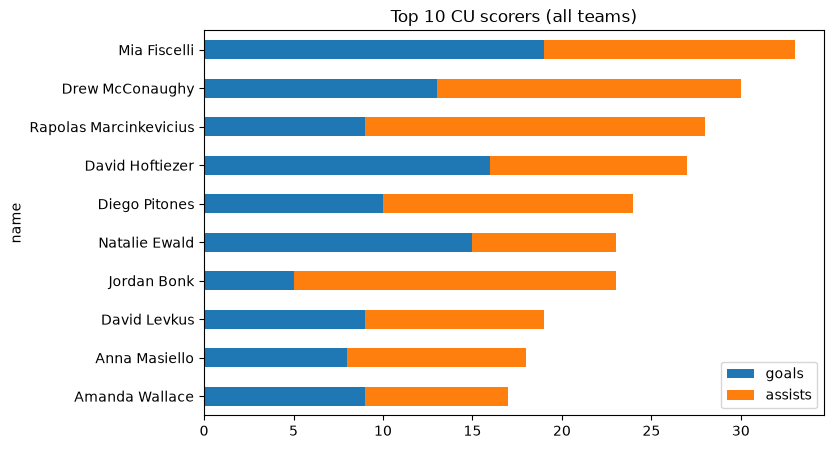

In [53]:
top10 = skaters.nlargest(10, "points").set_index("name")
top10[["goals", "assists"]].plot(kind="barh", stacked=True, figsize=(8, 5),
                                 title="Top 10 CU scorers (all teams)").invert_yaxis()

## 13. Challenge: Build a Standings Table

Hockey standings give **2 points for a win** and **1 point for an overtime or shootout loss** (OTL / SOL).

Using `played`, build one row per team-season with these columns: `GP`, `W`, `L`, `OTL`, `SOL`, `PTS`, `GF`, `GA`, `DIFF`. Sort it by `PTS` from highest to lowest.

*Hints:* start from the `record` table in section 7, `groupby().agg()` for goals, and `pd.concat([a, b], axis=1)` to put two tables side by side.

In [54]:
# ✅ Answer
standings = played.groupby(["team", "season"])["result"].value_counts().unstack(fill_value=0)
standings = standings[["W", "L", "OTL", "SOL"]]
standings["GP"] = standings.sum(axis=1)
standings["PTS"] = 2 * standings["W"] + standings["OTL"] + standings["SOL"]

goals = played.groupby(["team", "season"]).agg(GF=("cu_goals", "sum"), GA=("opp_goals", "sum"))
standings = pd.concat([standings, goals.astype(int)], axis=1)
standings["DIFF"] = standings["GF"] - standings["GA"]

standings[["GP", "W", "L", "OTL", "SOL", "PTS", "GF", "GA", "DIFF"]].sort_values("PTS", ascending=False)

GP   W   L  OTL  SOL  PTS   GF   GA  DIFF
team          season                                            
CU Women's D1 2024-25  26  19   6    1    0   39   87   53    34
CU Men's D1   2024-25  36  18  16    1    1   38  110  110     0
CU Men's D2   2023-24  28   8  20    0    0   16   94  114   -20
              2026-27   7   6   1    0    0   12   35   11    24

## Summary

| Task | Code |
|---|---|
| Load a CSV | `pd.read_csv("file.csv")` |
| First look | `df.head()`, `df.shape`, `df.info()`, `df.describe()` |
| One column (Series) | `df["col"]` |
| Several columns | `df[["a", "b"]]` |
| Filter rows | `df[df["col"] > 5]`, combined with `&`, `\|`, `~` |
| Filter + columns | `df.loc[condition, ["a", "b"]]` |
| Sort | `df.sort_values("col", ascending=False)`, `df.nlargest(5, "col")` |
| New column | `df["new"] = df["a"] - df["b"]` |
| Count values | `df["col"].value_counts()` |
| Group | `df.groupby("g")["col"].mean()`, `.agg(name=("col", "sum"))` |
| Missing data | `df.isna().sum()`, `dropna()`, `fillna()` |
| Dates | `pd.to_datetime(df["col"])`, `.dt.month_name()` |
| Join tables | `a.merge(b, on="key", how="left")` |
| Save | `df.to_csv("out.csv", index=False)` |